# First coupled HiRO-ACE → discharge run — diagnostics

Two `run_predict.py` runs over the same 10-year HiRO-ACE trajectory (`ic0000`/m0), 962 gauged
catchments, 3,200 days, differing only in how the forcing is normalized
(`hydro/pipeline/README.md` §5.1):

| run | `x_mean`/`x_std` from | `y_std` |
|---|---|---|
| **frozen** | the training data (real MSM/GARADAR) | training |
| **forcing** | the HiRO-ACE forcing itself | training |

Compared against observed discharge **distributionally** — HiRO-ACE is a scenario, not a reanalysis
of 2014–2023, so its dates carry no meaning and a date-matched score would measure calendar
coincidence, not skill.

**Question this notebook answers:** the aggregate predicted hydrograph peaks in spring while the
observed one peaks in July. Is that a rainfall problem (visible in the forcing itself), a snowmelt
problem, or an artefact of which catchments dominate the average?

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

DATA = Path("/Users/valentin/Desktop/UNRISK/Projects/coupled_model/climate-hydro-pipeline-data")
RUN = DATA / "hydro/results/coupled_run_2026-09-23"
FORCING = DATA / "processing/catchment_weighting/data/hiroace_dynamic_ic0000_full10yr_m0_v2.zarr"

SURFACE, INK, INK2, INK3 = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8983"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # dataviz palette slots 1-4
plt.rcParams.update({"figure.dpi": 130, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": INK3, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})

def style(ax, title=None, ylabel=None, xlabel=None):
    if title: ax.set_title(title, color=INK, fontsize=11, fontweight="bold", loc="left", pad=10)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.set_axisbelow(True)
    return ax

MONTHS = list("JFMAMJJASOND")
x = np.arange(12)

## Load — and align on catchment ID

**Trap worth naming:** the prediction and observation files store catchments in *different orders*.
Indexing them positionally silently compares unrelated rivers (it made small headwater catchments
look over-predicted 5×). Everything below is aligned by label first.

In [2]:
obs = xr.open_dataset(RUN / "observed_discharge_gauged.nc")["discharge_obs"].transpose("spatial", "time")
nodes = obs["spatial"].values
pred_fr = xr.open_dataset(RUN / "predictions_hiroace_full10yr_m0_frozen.nc")["discharge_pred"]
pred_fo = xr.open_dataset(RUN / "predictions_hiroace_full10yr_m0.nc")["discharge_pred"]
print("stored in the same order?", np.array_equal(pred_fr["spatial"].values, nodes))
pred_fr = pred_fr.sel(spatial=nodes)      # align by label
pred_fo = pred_fo.sel(spatial=nodes)
assert np.array_equal(pred_fr["spatial"].values, nodes)

meta = pd.read_csv(RUN / "gauged_catchment_meta.csv").set_index("node").loc[nodes]
flags = pd.read_csv(RUN / "catchment_training_flags.csv").set_index("node").loc[nodes]
real_forcing = pd.read_csv(RUN / "real_forcing_daily_gauged.csv", parse_dates=["time"]).set_index("time")
north = meta["lat"].values >= 37
in_training = flags["in_training"].values
print(f"catchments {len(nodes)} | northern (>=37N) {north.sum()} | dam-free, i.e. model was trained on them: {in_training.sum()}")

fds = xr.open_zarr(FORCING, consolidated=None).sel(spatial=nodes)
hiro_temp = np.mean([fds[f"hiroace_temp_4h_bin_{n}"].values for n in range(6)], axis=0)
hiro_prcp = np.mean([fds[f"hiroace_prcp_4h_bin_{n}"].values for n in range(6)], axis=0) * 24   # mm/day
hiro_time = pd.DatetimeIndex(fds["time"].values)

def monthly(values, times, mask=None):
    v = np.asarray(values)
    if v.shape[0] != len(times): v = v.T          # -> (time, catchment)
    if mask is not None: v = v[:, mask]
    d = pd.DataFrame(v, index=pd.DatetimeIndex(times))
    return d.groupby(d.index.month).mean().mean(axis=1).reindex(range(1, 13)).values

m_obs, m_fr, m_fo = (monthly(a.values, a["time"].values) for a in (obs, pred_fr, pred_fo))
m_hiro_p, m_hiro_t = monthly(hiro_prcp, hiro_time), monthly(hiro_temp, hiro_time)
m_real_p = real_forcing["garadar_prcp_daily"].groupby(real_forcing.index.month).mean().values
m_real_t = real_forcing["msm_temp_daily"].groupby(real_forcing.index.month).mean().values

stored in the same order? False
catchments 962 | northern (>=37N) 399 | dam-free, i.e. model was trained on them: 318


## 1. Discharge seasonal cycle

The normalization choice moves the *level* (frozen is far closer) but not the *shape*, so the
timing error is inherited from the forcing rather than created by normalization.

peak month — observed: 7 | frozen: 4


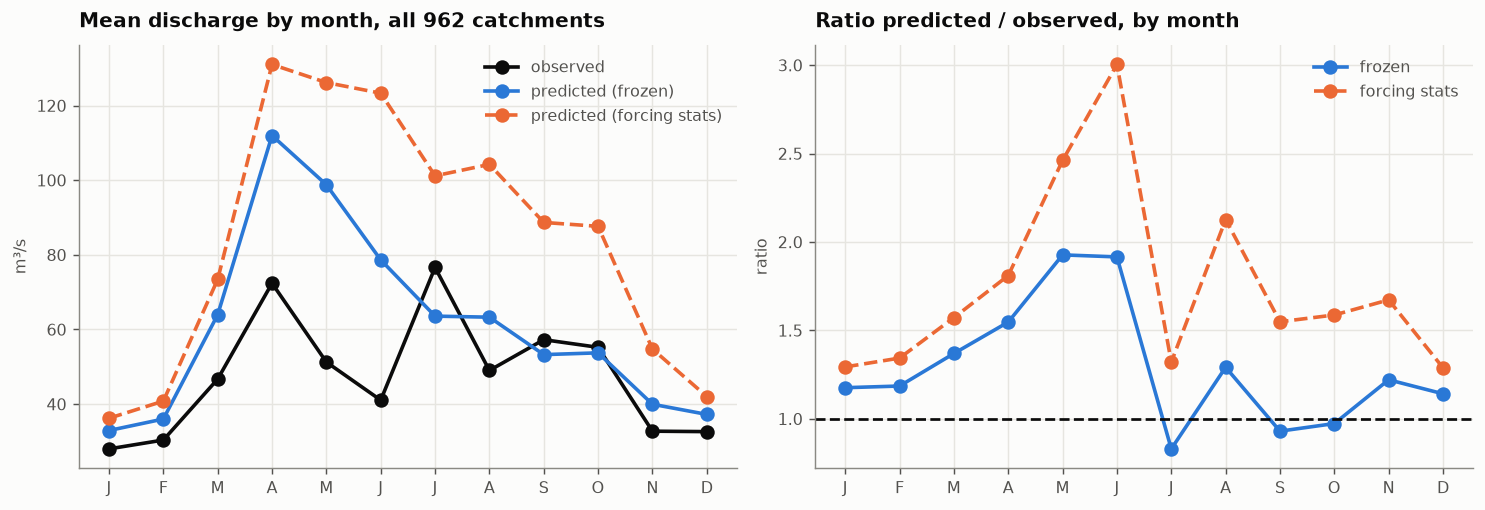

In [3]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.5, 4))
for a in (ax, bx):
    a.set_xticks(x); a.set_xticklabels(MONTHS)
ax.plot(x, m_obs, "o-", color=INK, lw=2, ms=7, label="observed")
ax.plot(x, m_fr, "o-", color=BLUE, lw=2, ms=7, label="predicted (frozen)")
ax.plot(x, m_fo, "o--", color=ORANGE, lw=2, ms=7, label="predicted (forcing stats)")
style(ax, "Mean discharge by month, all 962 catchments", "m³/s")
ax.legend(frameon=False, labelcolor=INK2)

bx.plot(x, m_fr / m_obs, "o-", color=BLUE, lw=2, ms=7, label="frozen")
bx.plot(x, m_fo / m_obs, "o--", color=ORANGE, lw=2, ms=7, label="forcing stats")
bx.axhline(1, color=INK, lw=1.5, ls="--")
style(bx, "Ratio predicted / observed, by month", "ratio")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()
print("peak month — observed:", int(np.argmax(m_obs)) + 1, "| frozen:", int(np.argmax(m_fr)) + 1)

## 2. Does the forcing explain it?

If the discharge error is inherited, it should be visible in the precipitation that drives it.

precip peak month: real 7 | HiRO-ACE 6
annual precip HiRO/real: 0.852
Jul-Sep precip ratio:   [0.58 0.72 0.61]


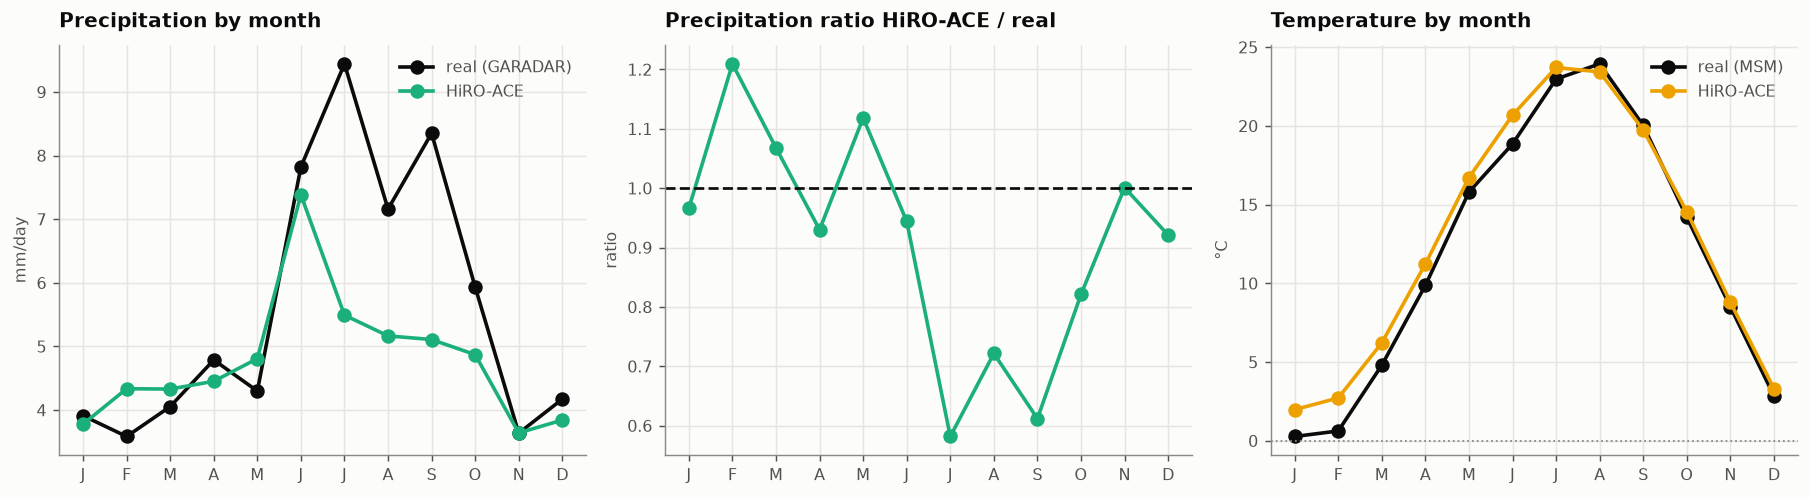

In [4]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(14, 3.9))
for a in (ax, bx, cx):
    a.set_xticks(x); a.set_xticklabels(MONTHS)
ax.plot(x, m_real_p, "o-", color=INK, lw=2, ms=7, label="real (GARADAR)")
ax.plot(x, m_hiro_p, "o-", color=AQUA, lw=2, ms=7, label="HiRO-ACE")
style(ax, "Precipitation by month", "mm/day"); ax.legend(frameon=False, labelcolor=INK2)

bx.plot(x, m_hiro_p / m_real_p, "o-", color=AQUA, lw=2, ms=7)
bx.axhline(1, color=INK, lw=1.5, ls="--")
style(bx, "Precipitation ratio HiRO-ACE / real", "ratio")

cx.plot(x, m_real_t, "o-", color=INK, lw=2, ms=7, label="real (MSM)")
cx.plot(x, m_hiro_t, "o-", color=YELLOW, lw=2, ms=7, label="HiRO-ACE")
cx.axhline(0, color=INK3, lw=1, ls=":")
style(cx, "Temperature by month", "°C"); cx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

print("precip peak month: real", int(np.argmax(m_real_p)) + 1, "| HiRO-ACE", int(np.argmax(m_hiro_p)) + 1)
print("annual precip HiRO/real:", round(m_hiro_p.mean() / m_real_p.mean(), 3))
print("Jul-Sep precip ratio:  ", np.round(m_hiro_p[6:9] / m_real_p[6:9], 2))

## 3. Who is the aggregate average actually describing?

Split two ways: geographically (snow-affected north vs rain-fed south) and by whether the model was
ever **trained** on the catchment — 644 of the 962 were excluded from training because they have a
dam upstream.

Northern (≥37°N)         obs peak  4 | pred peak  4 | annual ratio 1.35
Southern (<37°N)         obs peak  7 | pred peak  6 | annual ratio 1.19
Dam-free (trained on)    obs peak  7 | pred peak  4 | annual ratio 0.91
Dam-affected             obs peak  7 | pred peak  4 | annual ratio 1.32


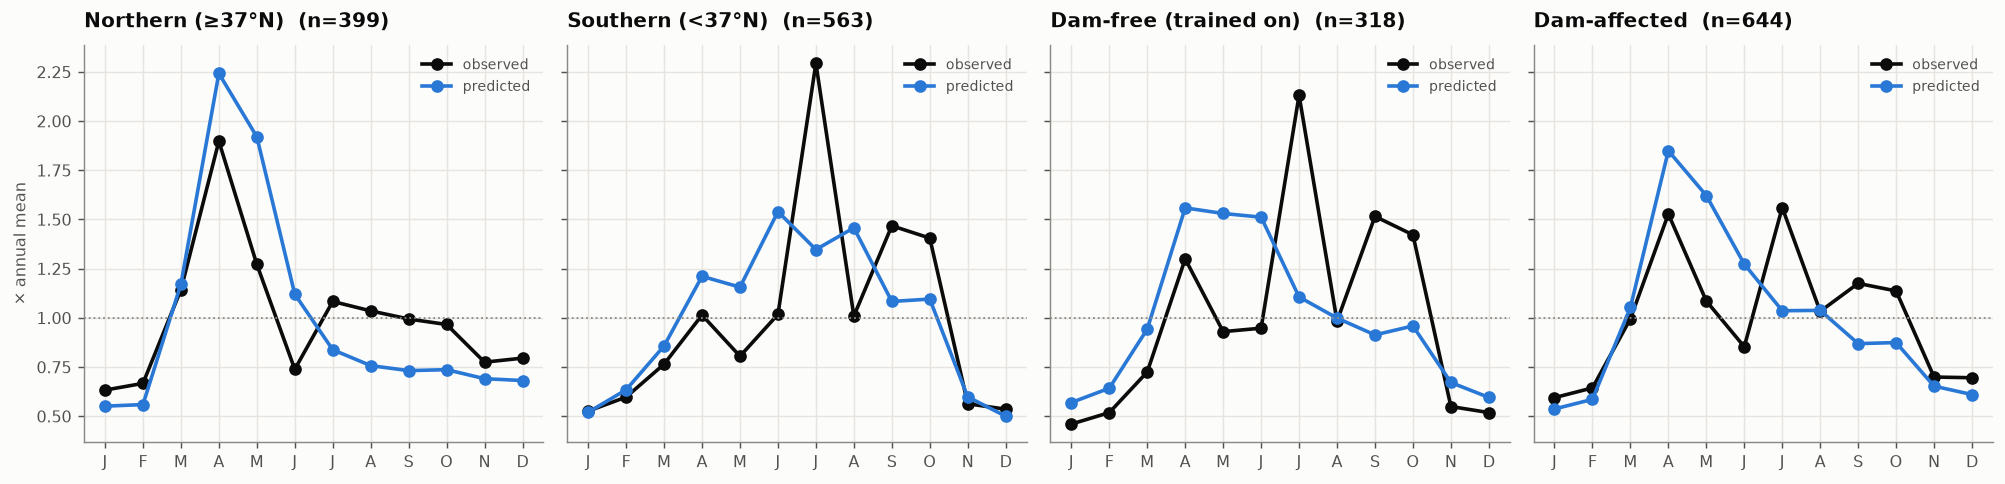

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.8), sharey=True)
groups = [("Northern (≥37°N)", north), ("Southern (<37°N)", ~north),
          ("Dam-free (trained on)", in_training), ("Dam-affected", ~in_training)]
for a, (name, mask) in zip(axes, groups):
    mo, mp = monthly(obs.values, obs["time"].values, mask), monthly(pred_fr.values, pred_fr["time"].values, mask)
    a.plot(x, mo / mo.mean(), "o-", color=INK, lw=2, ms=6, label="observed")
    a.plot(x, mp / mp.mean(), "o-", color=BLUE, lw=2, ms=6, label="predicted")
    a.axhline(1, color=INK3, lw=1, ls=":")
    a.set_xticks(x); a.set_xticklabels(MONTHS)
    style(a, f"{name}  (n={mask.sum()})", "× annual mean" if a is axes[0] else None)
    a.legend(frameon=False, labelcolor=INK2, fontsize=8)
    print(f"{name:24s} obs peak {int(np.argmax(mo))+1:2d} | pred peak {int(np.argmax(mp))+1:2d} "
          f"| annual ratio {mp.mean()/mo.mean():.2f}")
fig.tight_layout()

In [6]:
pm, om = np.nanmean(pred_fr.values, axis=1), np.nanmean(obs.values, axis=1)
ratio = pm / np.where(om > 0, om, np.nan)
ok = np.isfinite(ratio)
print(f"{'group':24s} {'median ratio':>13s} {'within +/-20%':>14s}")
for name, mask in groups + [("ALL", np.ones_like(north))]:
    s = mask.astype(bool) & ok
    print(f"{name:24s} {np.nanmedian(ratio[s]):13.2f} {100*np.mean(np.abs(ratio[s]-1) <= .2):13.0f}%")

group                     median ratio  within +/-20%
Northern (≥37°N)                  1.36            30%
Southern (<37°N)                  1.07            47%
Dam-free (trained on)             1.05            52%
Dam-affected                      1.30            34%
ALL                               1.20            40%


## 4. Flow-duration curves

Per catchment, then the median across catchments at each exceedance level, so one large river
cannot dominate.

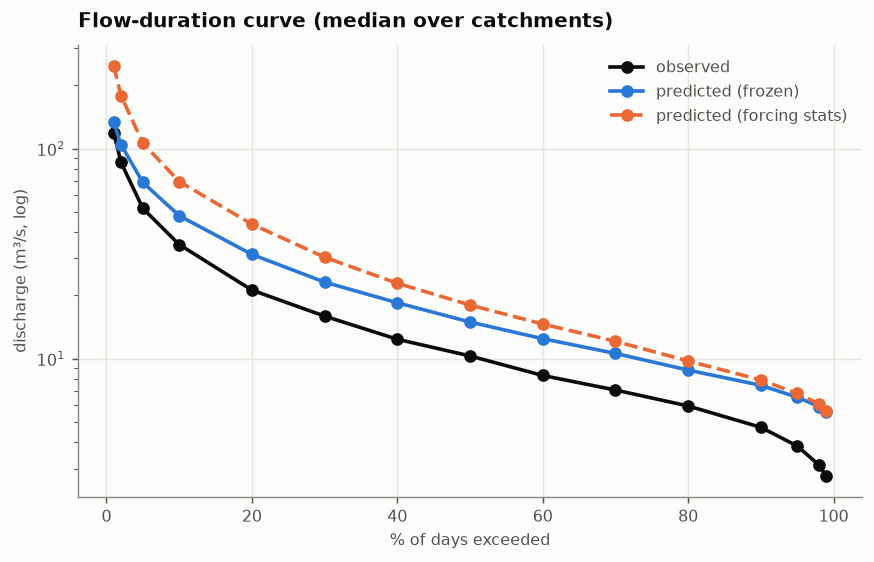

In [7]:
qs = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99])
def fdc(arr):
    with np.errstate(invalid="ignore"):
        return np.nanmedian(np.nanquantile(arr, 1 - qs, axis=1), axis=1)

fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.plot(qs * 100, fdc(obs.values), "o-", color=INK, lw=2, ms=6, label="observed")
ax.plot(qs * 100, fdc(pred_fr.values), "o-", color=BLUE, lw=2, ms=6, label="predicted (frozen)")
ax.plot(qs * 100, fdc(pred_fo.values), "o--", color=ORANGE, lw=2, ms=6, label="predicted (forcing stats)")
ax.set_yscale("log")
style(ax, "Flow-duration curve (median over catchments)", "discharge (m³/s, log)", "% of days exceeded")
ax.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

## 5. What CV is, and why it matters

**CV = standard deviation ÷ mean** — dimensionless, so it measures how *flashy* a river is
regardless of its size. Observed median is ~1.5: day-to-day swings are one and a half times the
average flow.

- **frozen stats** — level close, CV too low: the hydrograph is too smooth.
- **forcing stats** — CV almost exact, every flow inflated ≈1.7×: right shape, wrong scale.

Both follow from HiRO-ACE's precipitation standard deviation being only ~50–60% of the real one.

frozen  : median CV 1.20 (obs 1.53), mean-flow ratio 1.20, within +/-20%: 40%
forcing : median CV 1.51 (obs 1.53), mean-flow ratio 1.72, within +/-20%: 8%


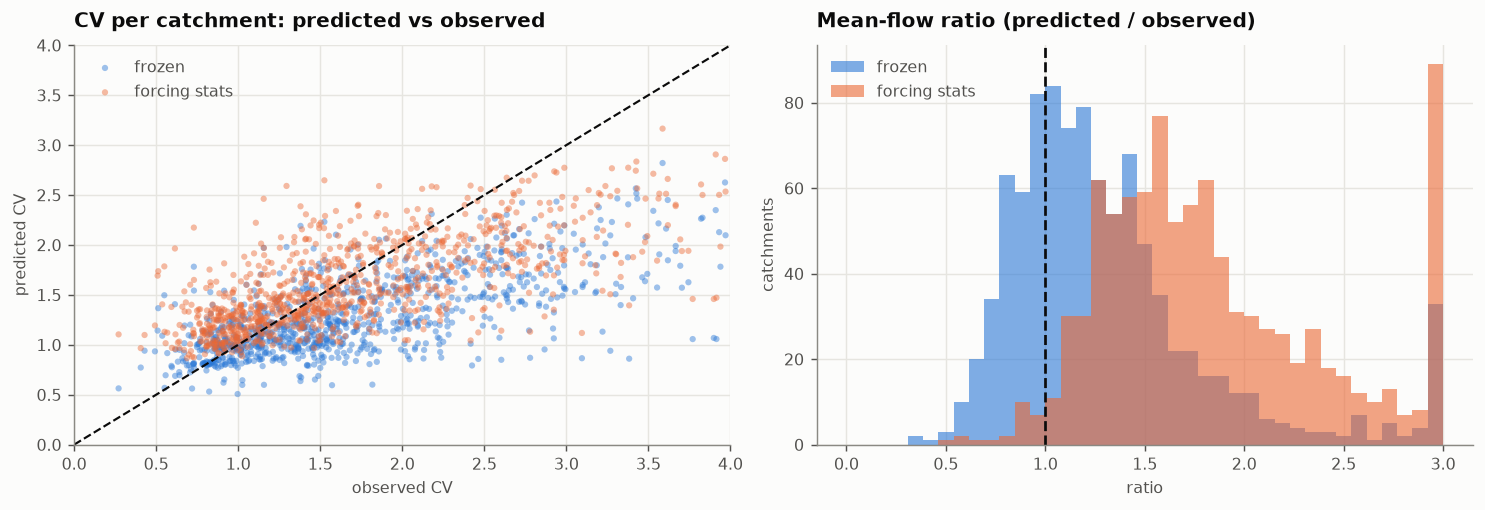

In [8]:
stats_fr = pd.read_csv(RUN / "pred_vs_obs_stats_frozen.csv")
stats_fo = pd.read_csv(RUN / "pred_vs_obs_stats.csv")
keep = (stats_fr["obs_n_valid"] >= 365) & (stats_fr["obs_mean"] > 0)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.5, 4))
lim = [0, 4]
ax.scatter(stats_fr.loc[keep, "obs_cv"], stats_fr.loc[keep, "pred_cv"], s=12, alpha=.45,
           color=BLUE, edgecolors="none", label="frozen")
ax.scatter(stats_fo.loc[keep, "obs_cv"], stats_fo.loc[keep, "pred_cv"], s=12, alpha=.45,
           color=ORANGE, edgecolors="none", label="forcing stats")
ax.plot(lim, lim, color=INK, lw=1.2, ls="--")
ax.set_xlim(lim); ax.set_ylim(lim)
style(ax, "CV per catchment: predicted vs observed", "predicted CV", "observed CV")
ax.legend(frameon=False, labelcolor=INK2)

bins = np.linspace(0, 3, 40)
bx.hist(stats_fr.loc[keep, "ratio_mean"].clip(0, 3), bins=bins, color=BLUE, alpha=.6, label="frozen")
bx.hist(stats_fo.loc[keep, "ratio_mean"].clip(0, 3), bins=bins, color=ORANGE, alpha=.6, label="forcing stats")
bx.axvline(1, color=INK, lw=1.5, ls="--")
style(bx, "Mean-flow ratio (predicted / observed)", "catchments", "ratio")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

for nm, s in (("frozen", stats_fr), ("forcing", stats_fo)):
    d = s[keep]
    print(f"{nm:8s}: median CV {d['pred_cv'].median():.2f} (obs {d['obs_cv'].median():.2f}), "
          f"mean-flow ratio {d['ratio_mean'].median():.2f}, within +/-20%: "
          f"{100*((d['ratio_mean']-1).abs() <= .2).mean():.0f}%")

## Conclusions

1. **The spring peak is not snowmelt mistiming.** Northern, snow-affected catchments peak in April
   in *both* observation and prediction — the melt timing is right. The aggregate "April vs July"
   gap is mostly northern big rivers dominating an unweighted average.
2. **It is inherited from the precipitation.** HiRO-ACE's rainfall peaks in June against July in
   reality, and is drastically short in the late-summer rainy/typhoon season (Jul–Sep ratios
   ~0.58–0.72; annual 0.85). Discharge follows exactly: over-predicted May–June, under-predicted
   Jul–Oct.
3. **Dam-free catchments — the ones the model was actually trained on — are the best reproduced**
   (median ratio ≈1.05, about half within ±20%), while dam-affected ones sit ≈1.3. Reservoir
   regulation is not represented, which is expected rather than a defect.
4. **Variance, not just mean, is the headline forcing deficit** (§5). That is what a bias correction
   has to fix; a mean-only correction would leave the hydrograph too smooth.

**For bias correction:** quantile mapping applied **per calendar month** would address the seasonal
misplacement and the variance deficit together. A pooled, annual correction would fix neither.

---
# Part II — what the coupled output looks like, river by river

Everything above is aggregated (monthly means, medians over catchments). This part looks at the
hydrographs themselves, then at properties the aggregates hide: interannual variability and drift,
flood timing and magnitude, flashiness, and where in Japan the bias sits.

**Reminder when reading the time series:** HiRO-ACE is a scenario, so a predicted flood on
2018-07-06 has nothing to do with the real one on that date. Compare *character* (flow level,
seasonality, peak height and frequency, how fast recessions fall) — never individual events.

**Record lengths differ:** observations cover 2015-01-01 → 2020-12-31 (6 years, ~90% valid);
the prediction covers 2015-01-02 → 2023-10-06 (3,200 days — the forcing starts 2014-01-02, and
the first year is used as the model's init window). Annual statistics use full years only.

In [9]:
stats = stats_fr.set_index("node").loc[nodes]
flags_all = flags.copy()
lat, lon = meta["lat"].values, meta["lon"].values
obs_t, pred_t = pd.DatetimeIndex(obs["time"].values), pd.DatetimeIndex(pred_fr["time"].values)
O, P = obs.values, pred_fr.transpose("spatial", "time").values          # (catchment, time)
P_fo = pred_fo.transpose("spatial", "time").values
assert O.shape[0] == P.shape[0] == len(nodes)

# --- representative gauges, picked by rule so the choice is reproducible -----------------------
good = (stats["obs_n_valid"] >= 0.9 * len(obs_t)).values & (stats["obs_mean"] > 0).values
s = stats.assign(lat=lat, lon=lon, dam_free=in_training, good=good, area=meta["catchment_area"].values,
                 n_up=flags["n_upstream"].values)
g = s[s["good"]]
GAUGES = {
    "Large northern river (snowmelt)":   g[g["lat"] >= 37].obs_mean.idxmax(),
    "Large southern river (typhoon)":    g[g["lat"] < 34.5].obs_mean.idxmax(),
    "Dam-free, well reproduced":         g[g["dam_free"] & g.obs_mean.between(10, 100)]
                                            .ratio_mean.sub(1).abs().idxmin(),
    "Dam-affected, regulated flow":      g[~g["dam_free"] & (g.obs_mean > 20)]
                                            .pipe(lambda d: (d.pred_cv / d.obs_cv)).idxmax(),
    "Small headwater (dam-free)":        g[g["dam_free"] & (g["n_up"] <= 2)].obs_mean.idxmin(),
    "Typical catchment (median bias)":   g.ratio_mean.sub(g.ratio_mean.median()).abs().idxmin(),
}
# Override any entry by hand, e.g. GAUGES["My river"] = 234034390
gidx = {name: int(np.where(nodes == n)[0][0]) for name, n in GAUGES.items()}
print(s.loc[list(GAUGES.values()), ["lat", "lon", "n_up", "dam_free", "obs_mean", "pred_mean",
                                     "ratio_mean", "obs_cv", "pred_cv"]]
       .set_axis(list(GAUGES), axis=0).round(2).to_string())

                                   lat     lon  n_up  dam_free  obs_mean  pred_mean  ratio_mean  obs_cv  pred_cv
Large northern river (snowmelt)  37.45  138.83   255     False    571.69     724.00        1.27    0.64     0.70
Large southern river (typhoon)   31.95  131.40    60     False    195.40     153.17        0.78    1.39     0.94
Dam-free, well reproduced        37.06  138.88     8      True     35.86      36.64        1.02    0.80     0.81
Dam-affected, regulated flow     43.08  144.43    43     False     47.57      55.23        1.16    0.27     0.56
Small headwater (dam-free)       43.00  141.31     0      True      0.21       0.26        1.29    1.11     1.49
Typical catchment (median bias)  39.61  140.16   116     False    251.66     297.77        1.18    0.86     0.79


## 6. Where the gauges are, and where the bias sits

Colour is the per-catchment mean-flow ratio (frozen run) on a log scale: blue under-predicted,
red over-predicted, grey ≈ right. Ringed points are the gauges plotted below.

1: Large northern river (snowmelt)
2: Large southern river (typhoon)
3: Dam-free, well reproduced
4: Dam-affected, regulated flow
5: Small headwater (dam-free)
6: Typical catchment (median bias)


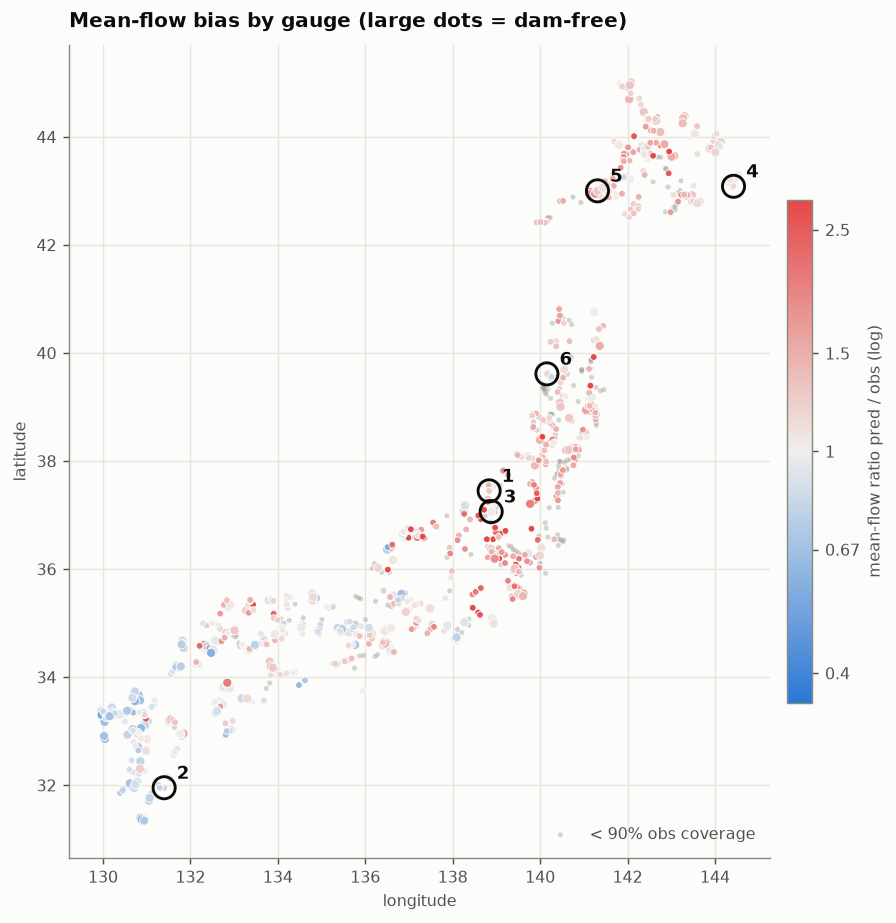

In [10]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
RED, MID = "#e34948", "#f0efec"
div = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, MID, RED])
lr = np.log2(s["ratio_mean"].where(s["good"])).values

fig, ax = plt.subplots(figsize=(7.2, 7.2))
ax.scatter(lon[~good], lat[~good], s=8, color=INK3, alpha=.35, edgecolors="none", label="< 90% obs coverage")
sc = ax.scatter(lon[good], lat[good], c=lr[good], cmap=div, norm=TwoSlopeNorm(0, -1.5, 1.5),
                s=np.where(in_training[good], 26, 14), edgecolors=SURFACE, linewidths=.5)
for k, (name, i) in enumerate(gidx.items(), 1):
    ax.scatter(lon[i], lat[i], s=150, facecolors="none", edgecolors=INK, linewidths=1.6)
    ax.annotate(str(k), (lon[i], lat[i]), xytext=(7, 5), textcoords="offset points",
                fontsize=10, fontweight="bold", color=INK)
cb = fig.colorbar(sc, ax=ax, shrink=.6, pad=.02)
cb.set_ticks(np.log2([1/2.5, 1/1.5, 1, 1.5, 2.5])); cb.set_ticklabels(["0.4", "0.67", "1", "1.5", "2.5"])
cb.set_label("mean-flow ratio pred / obs (log)", color=INK2)
ax.set_aspect(1 / np.cos(np.deg2rad(36)))
style(ax, "Mean-flow bias by gauge (large dots = dam-free)", "latitude", "longitude")
ax.legend(frameon=False, labelcolor=INK2, loc="lower right")
fig.tight_layout()
for k, name in enumerate(GAUGES, 1):
    print(f"{k}: {name}")

## 7. Hydrographs over the full record

Log scale so low flows and floods are both readable. Observed (black) stops at the end of 2020;
predicted (blue, frozen stats) runs to October 2023.

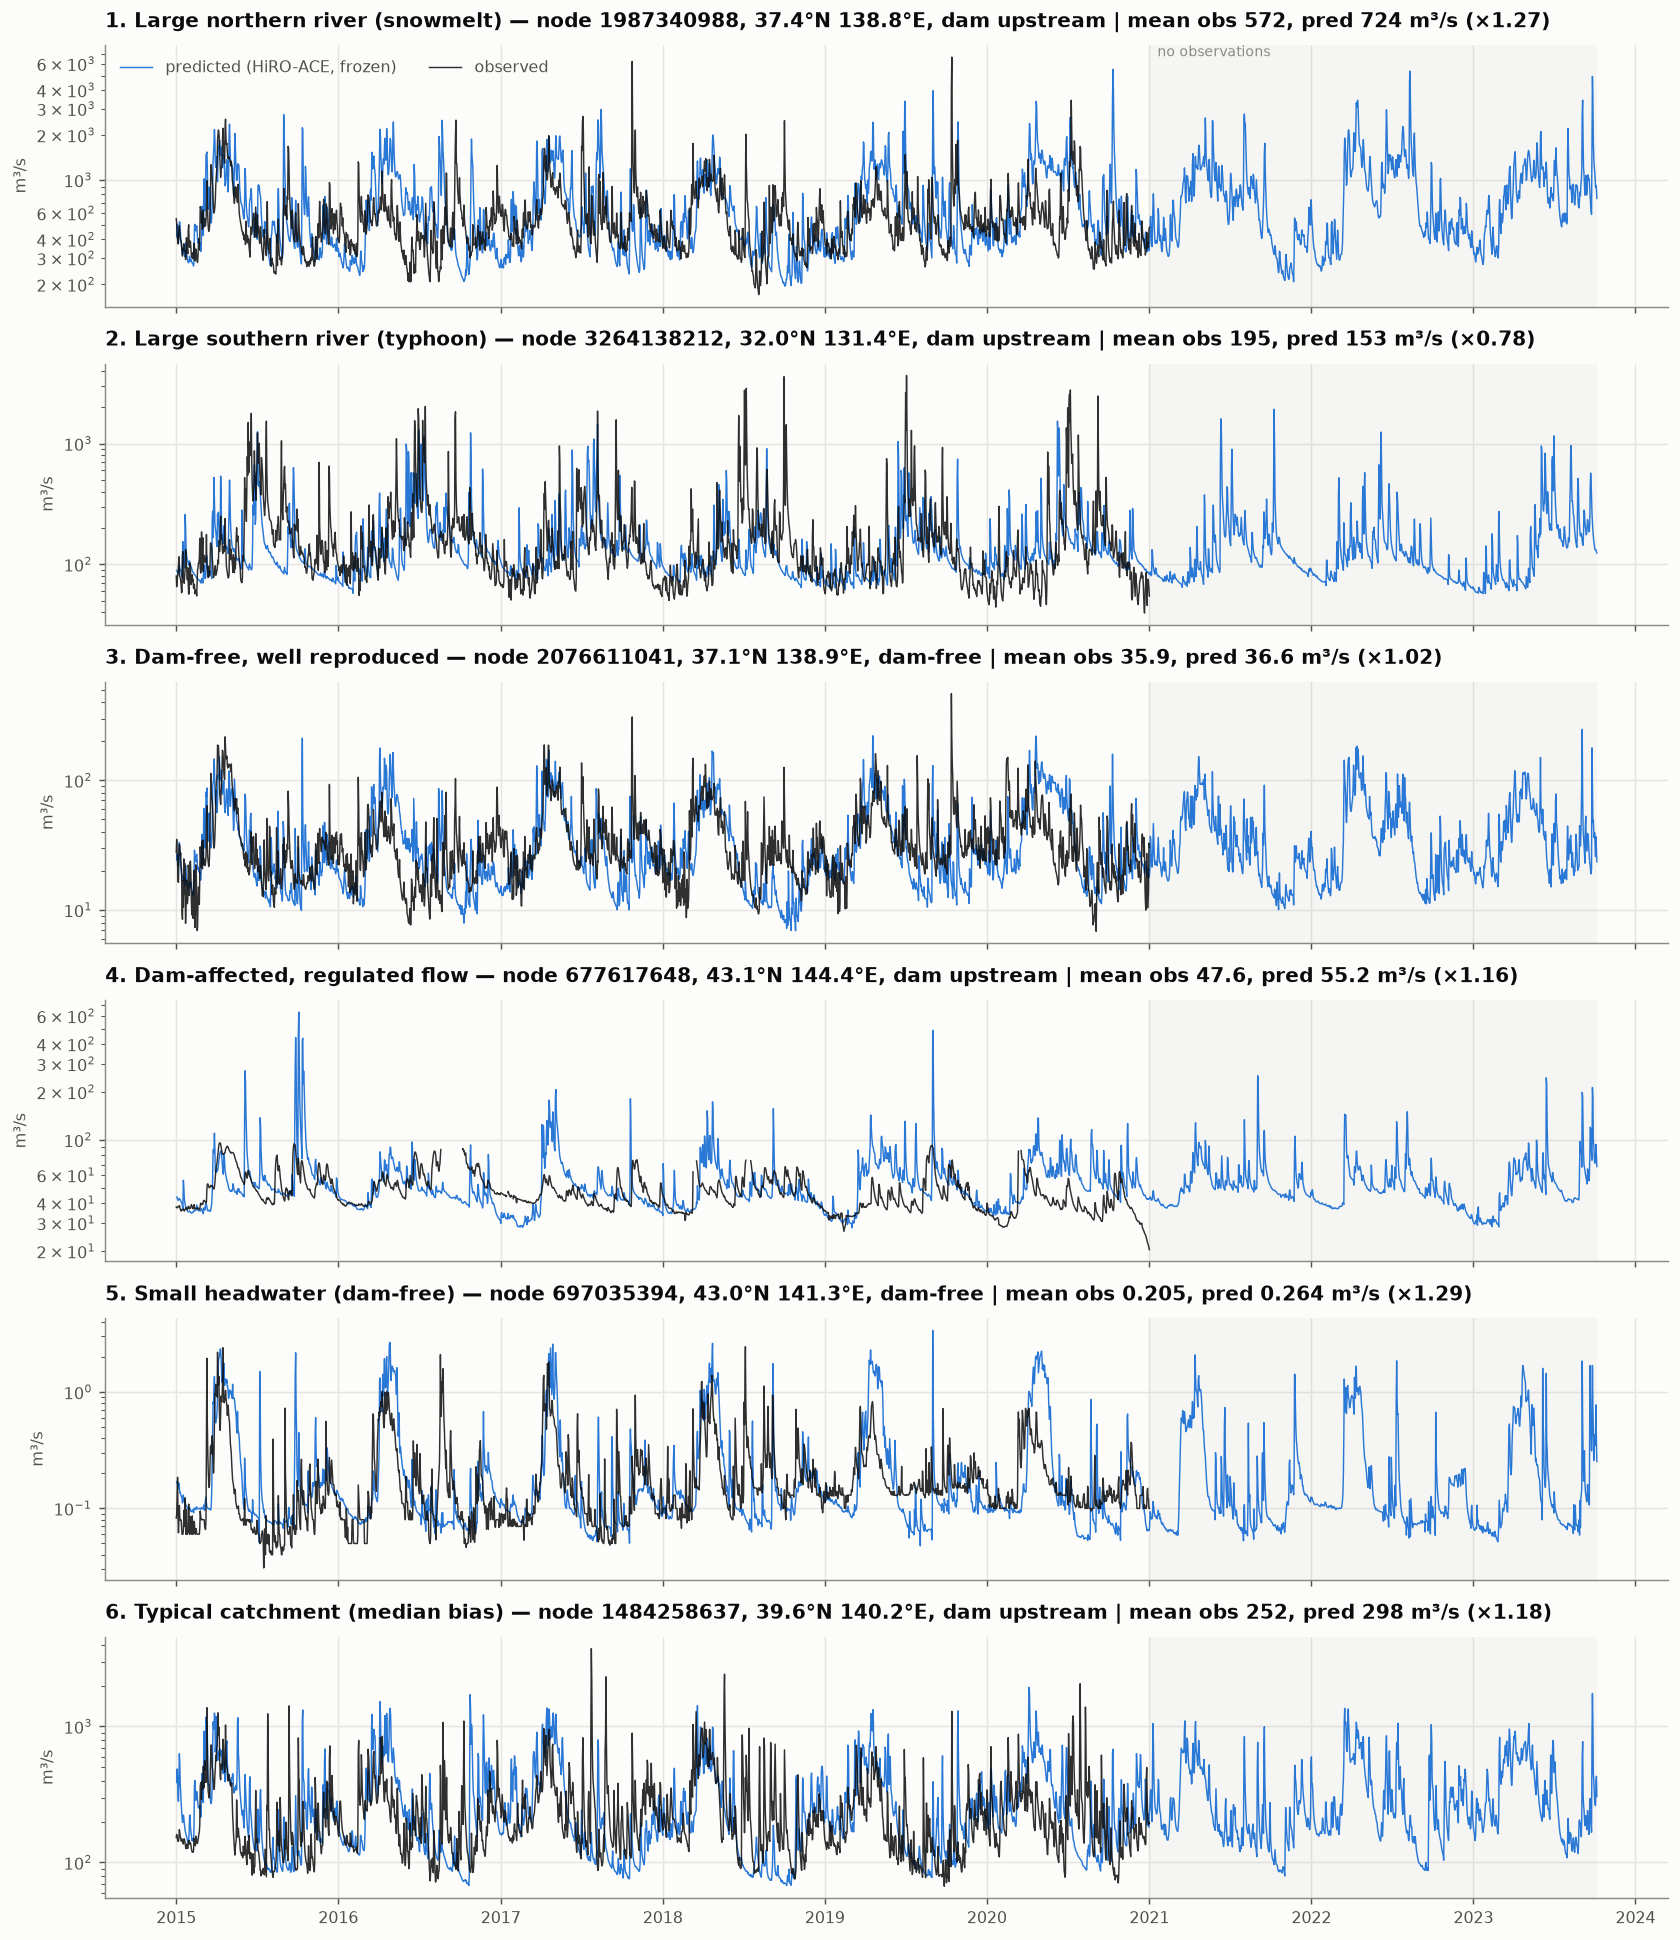

In [11]:
def gauge_title(k, name, i):
    r = stats.iloc[i]
    return (f"{k}. {name} — node {nodes[i]}, {lat[i]:.1f}°N {lon[i]:.1f}°E, "
            f"{'dam-free' if in_training[i] else 'dam upstream'} | mean obs {r.obs_mean:.3g}, "
            f"pred {r.pred_mean:.3g} m³/s (×{r.ratio_mean:.2f})")

fig, axes = plt.subplots(len(gidx), 1, figsize=(13, 2.5 * len(gidx)), sharex=True)
for k, (a, (name, i)) in enumerate(zip(axes, gidx.items()), 1):
    a.plot(pred_t, P[i], color=BLUE, lw=.8, label="predicted (HiRO-ACE, frozen)")
    a.plot(obs_t, O[i], color=INK, lw=.8, alpha=.85, label="observed")
    a.axvspan(obs_t[-1], pred_t[-1], color=INK3, alpha=.06, lw=0)
    a.set_yscale("log")
    style(a, gauge_title(k, name, i), "m³/s")
    a.title.set_fontsize(9.5)
axes[0].legend(frameon=False, labelcolor=INK2, ncol=2, loc="upper left")
axes[0].text(obs_t[-1], 1.0, "  no observations", transform=axes[0].get_xaxis_transform(),
             va="top", color=INK3, fontsize=8)
fig.tight_layout()

## 8. One-year zoom

Linear scale, one calendar year (`ZOOM_YEAR`, must be ≤ 2020 to have observations). The bars on
top are HiRO-ACE daily precipitation over the gauge's **own local catchment** only — a proxy for
what drives the predicted hydrograph; for large rivers most of the water comes from upstream
catchments not shown here. Real precipitation per catchment isn't in the run outputs.

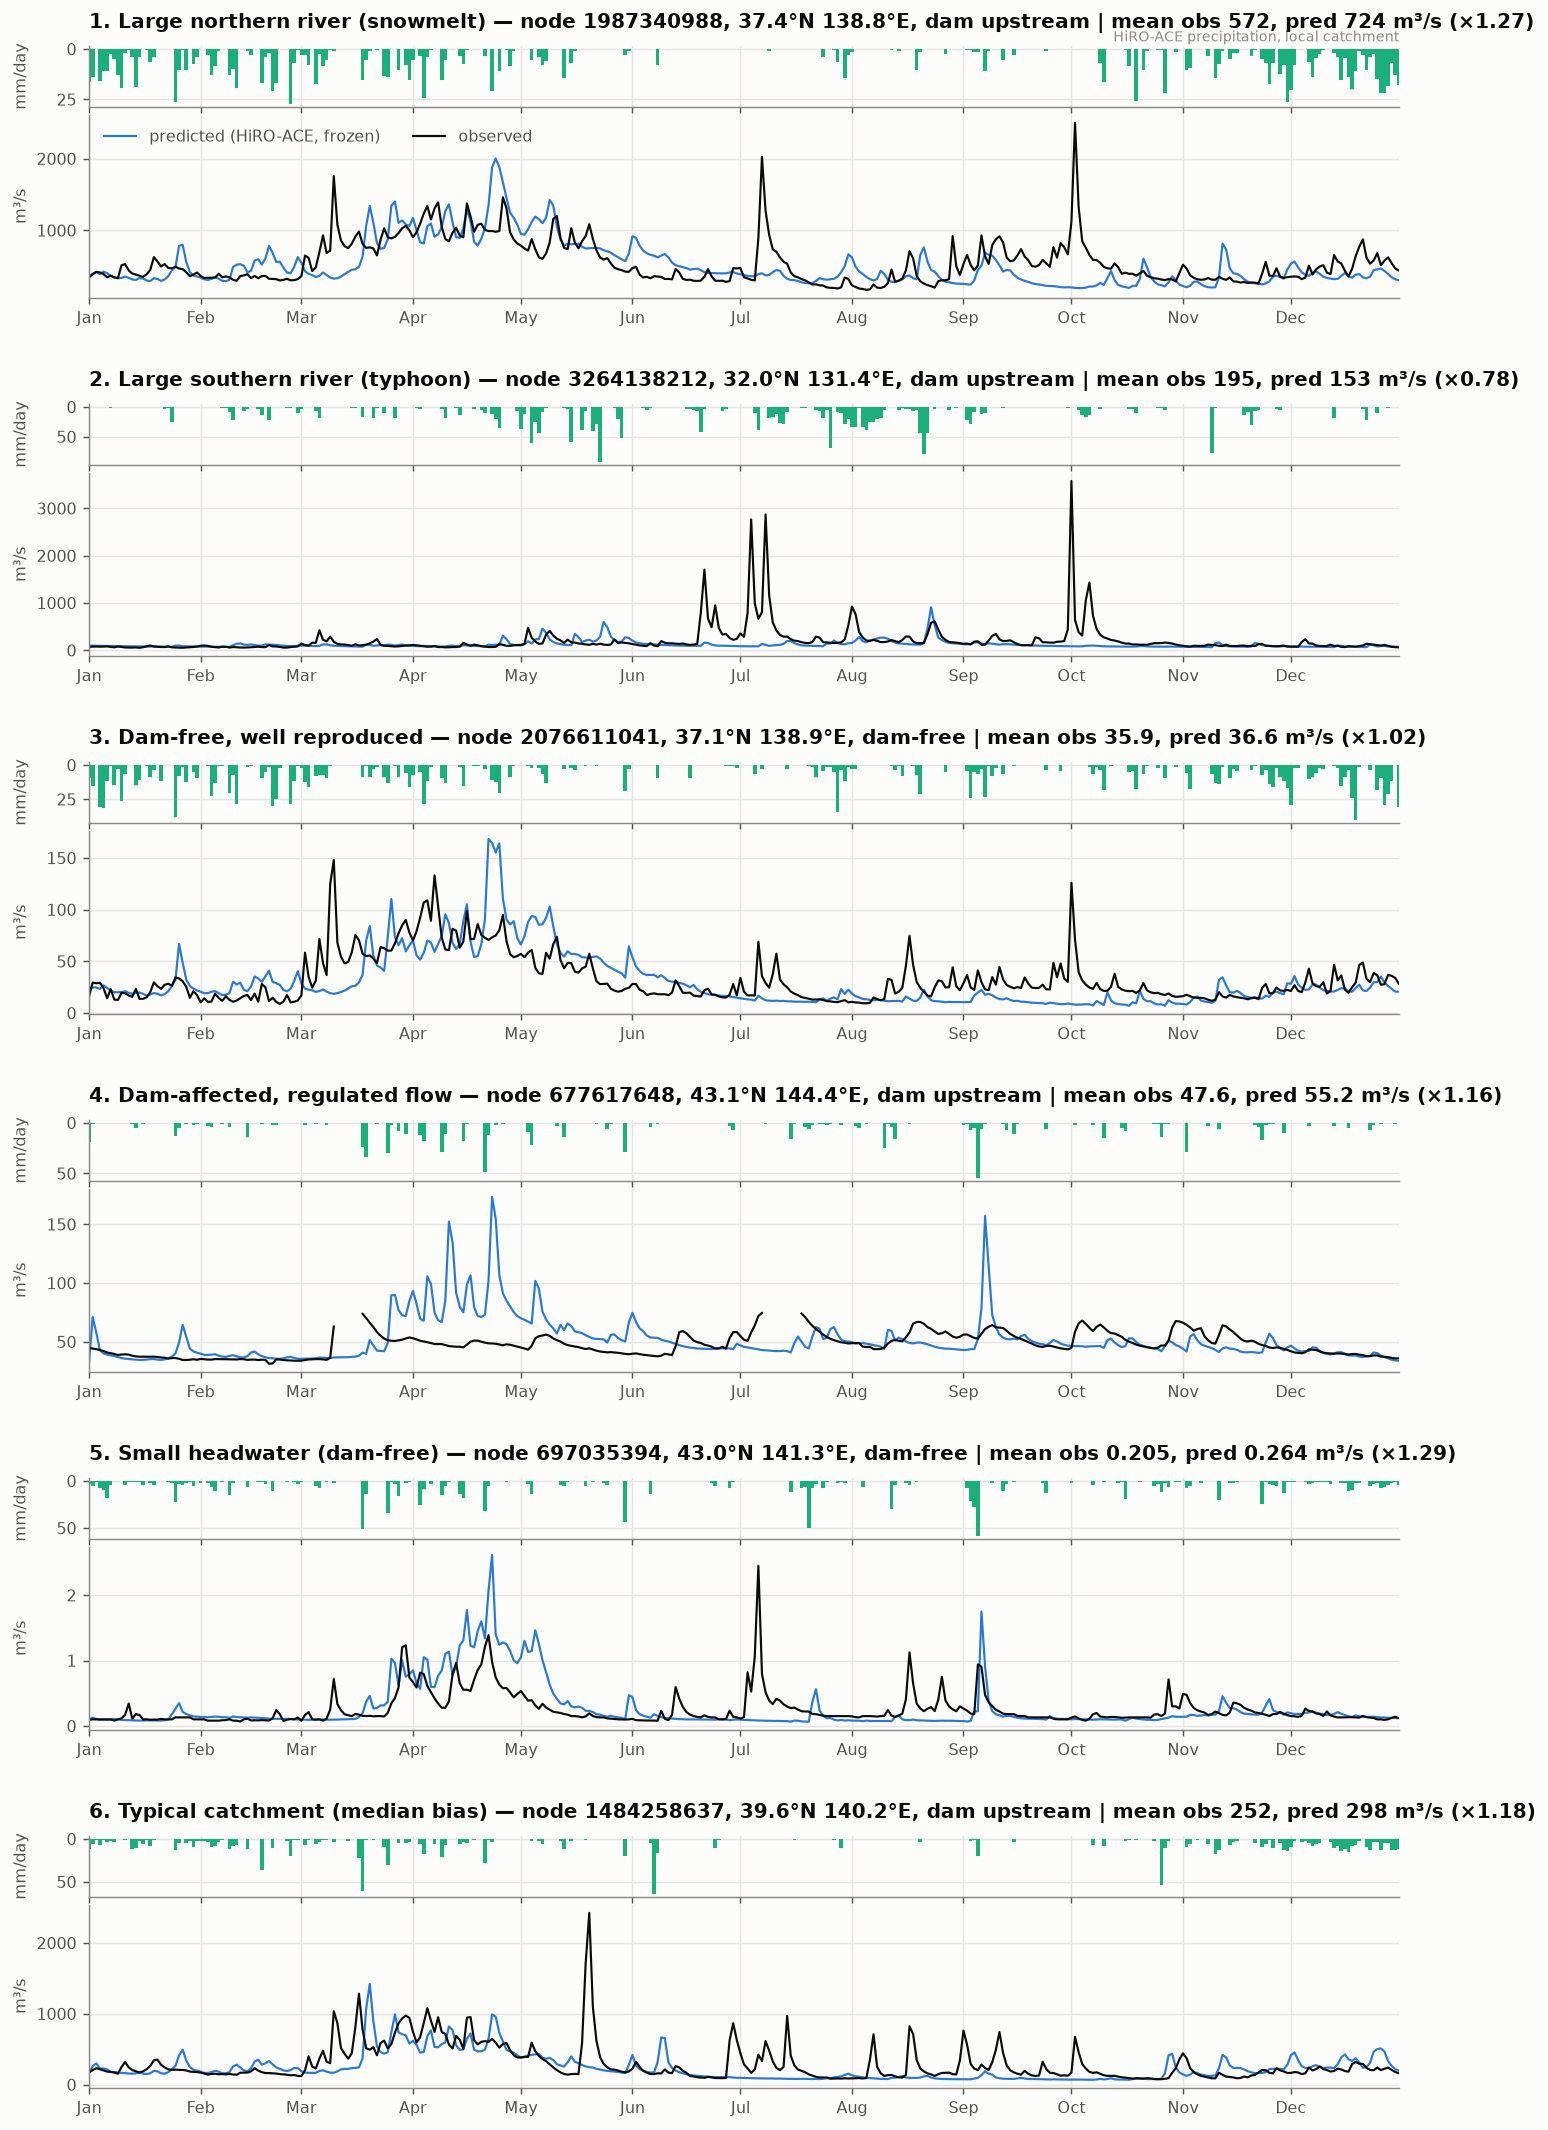

In [12]:
ZOOM_YEAR = 2018
t0, t1 = pd.Timestamp(f"{ZOOM_YEAR}-01-01"), pd.Timestamp(f"{ZOOM_YEAR}-12-31")
po, pp, ph = (obs_t >= t0) & (obs_t <= t1), (pred_t >= t0) & (pred_t <= t1), (hiro_time >= t0) & (hiro_time <= t1)
hp = hiro_prcp if hiro_prcp.shape[0] == len(hiro_time) else hiro_prcp.T     # (time, catchment)

import matplotlib.dates as mdates
fig = plt.figure(figsize=(13, 3.4 * len(gidx)))
outer = fig.add_gridspec(len(gidx), 1, hspace=.42)
for k, (name, i) in enumerate(gidx.items()):
    inner = outer[k].subgridspec(2, 1, height_ratios=[1, 3], hspace=.06)
    ra = fig.add_subplot(inner[0]); qa = fig.add_subplot(inner[1], sharex=ra)
    ra.bar(hiro_time[ph], hp[ph, i], width=1, color=AQUA, lw=0)
    ra.invert_yaxis(); ra.tick_params(labelbottom=False)
    style(ra, gauge_title(k + 1, name, i), "mm/day"); ra.title.set_fontsize(9.5)
    qa.plot(pred_t[pp], P[i, pp], color=BLUE, lw=1.2, label="predicted (HiRO-ACE, frozen)")
    qa.plot(obs_t[po], O[i, po], color=INK, lw=1.2, label="observed")
    style(qa, None, "m³/s")
    qa.xaxis.set_major_locator(mdates.MonthLocator()); qa.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    if k == 0:
        qa.legend(frameon=False, labelcolor=INK2, ncol=2, loc="upper left")
        ra.text(1, 1.02, "HiRO-ACE precipitation, local catchment", transform=ra.transAxes,
                ha="right", va="bottom", color=INK3, fontsize=8)
    qa.set_xlim(t0, t1)
fig.align_ylabels()

## 9. Interannual variability and drift

Annual mean flow per catchment, divided by that catchment's long-term mean, so every river weighs
the same. Two questions: does HiRO-ACE have realistic **year-to-year variability** (wet years,
dry years), and does the emulator **drift** over the 9-year run (a trend in the predicted
annual means that the observations can't have)?

median interannual CV — observed 0.199 | predicted 0.188  (note: 6 vs 8 years)
trend in predicted median annual mean: -0.9% of long-term mean per year


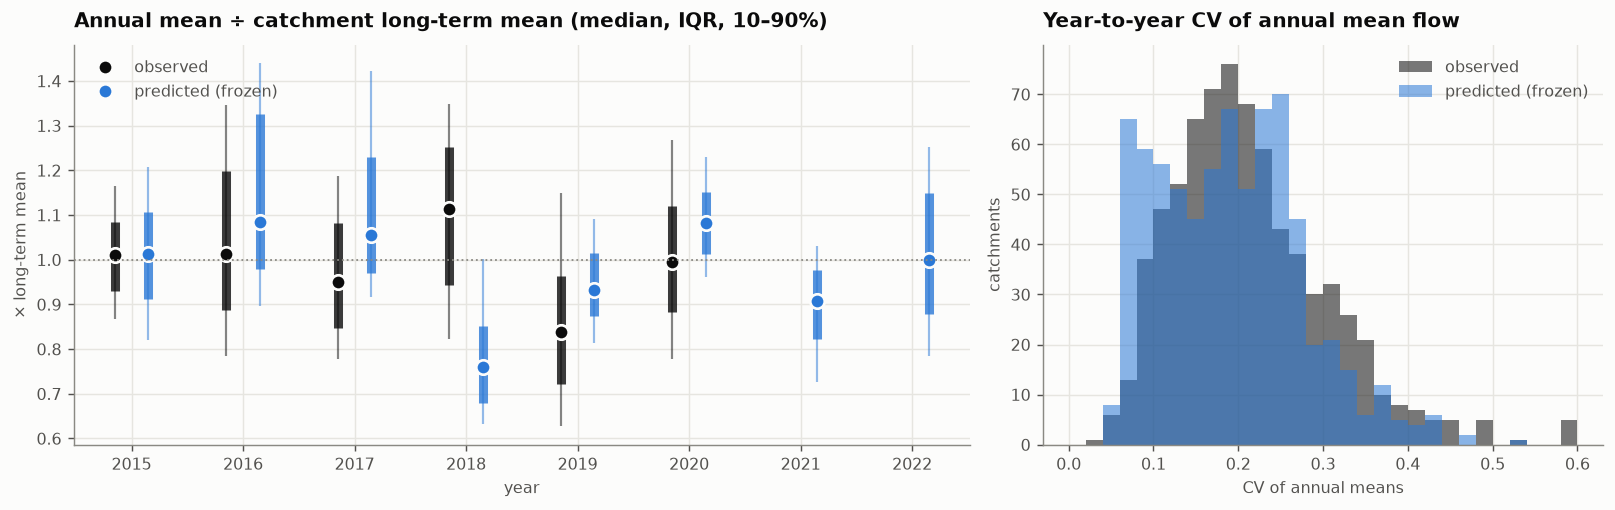

In [13]:
def annual_means(arr, times, min_days=330):
    d = pd.DataFrame(arr.T, index=times)
    n = d.notna().groupby(d.index.year).sum()
    return d.groupby(d.index.year).mean().where(n >= min_days)      # (year, catchment)

ao, ap = annual_means(O, obs_t), annual_means(P, pred_t)
ao, ap = ao.loc[:, good], ap.loc[:, good]
ap = ap.loc[ap.notna().mean(axis=1) > .9]                        # drop the partial 2023
no, npd = ao / ao.mean(), ap / ap.mean()
iav_o, iav_p = (ao.std() / ao.mean()), (ap.std() / ap.mean())

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.6, 1]})
for frame, col, lab, off in ((no, INK, "observed", -.15), (npd, BLUE, "predicted (frozen)", .15)):
    yrs = frame.index.values
    q = frame.quantile([.1, .25, .5, .75, .9], axis=1)
    ax.vlines(yrs + off, q.loc[.1], q.loc[.9], color=col, lw=1.2, alpha=.5)
    ax.vlines(yrs + off, q.loc[.25], q.loc[.75], color=col, lw=5, alpha=.8)
    ax.plot(yrs + off, q.loc[.5], "o", color=col, ms=8, mec=SURFACE, mew=1.5, label=lab)
ax.axhline(1, color=INK3, lw=1, ls=":")
style(ax, "Annual mean ÷ catchment long-term mean (median, IQR, 10–90%)", "× long-term mean", "year")
ax.legend(frameon=False, labelcolor=INK2, loc="upper left")
ax.set_xticks(npd.index.values)

bins = np.linspace(0, .6, 31)
bx.hist(iav_o.clip(upper=.6), bins=bins, color=INK, alpha=.55, label="observed")
bx.hist(iav_p.clip(upper=.6), bins=bins, color=BLUE, alpha=.55, label="predicted (frozen)")
style(bx, "Year-to-year CV of annual mean flow", "catchments", "CV of annual means")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

agg = npd.median(axis=1)
slope = np.polyfit(agg.index.values, agg.values, 1)[0]
print(f"median interannual CV — observed {iav_o.median():.3f} | predicted {iav_p.median():.3f}  "
      f"(note: 6 vs {len(ap)} years)")
print(f"trend in predicted median annual mean: {100*slope:+.1f}% of long-term mean per year")

## 10. Floods — timing and size of the annual maximum

The seasonal-cycle plot (§1) is about average flow. Floods are a separate question: in Japan
the largest flow of the year usually comes with the Baiu front (June–July) or a typhoon
(August–October). Left: in which month each catchment's annual maximum falls, across all
catchment-years. Right: is the median annual peak biased the same way as the mean flow?

share of annual maxima in Aug–Oct: observed 48% | predicted 39%
median annual-peak ratio: 0.87 (mean-flow ratio 1.18)


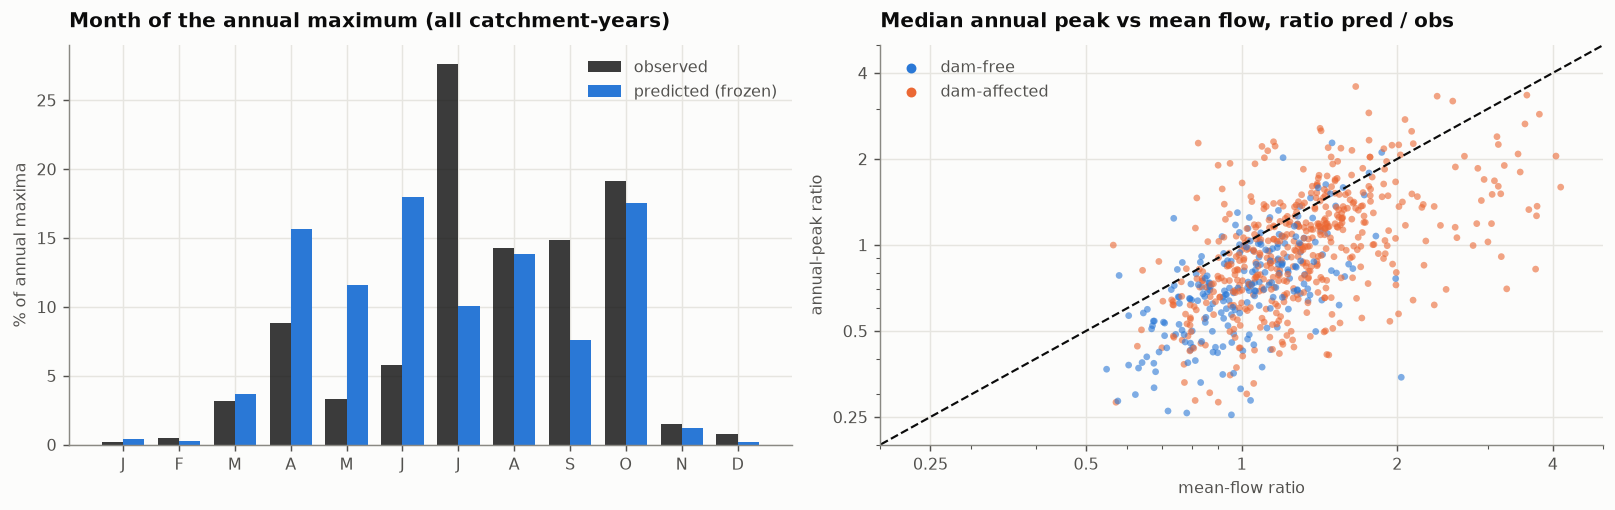

In [14]:
def ratio_ticks(a, axis):
    t = [.25, .5, 1, 2, 4]
    getattr(a, f"set_{axis}ticks")(t); getattr(a, f"set_{axis}ticklabels")([f"{v:g}" for v in t])
    getattr(a, f"{axis}axis").set_minor_formatter(plt.NullFormatter())

def annual_max(arr, times, min_days=330):
    d = pd.DataFrame(arr.T, index=times)
    n = d.notna().groupby(d.index.year).sum()
    mx = d.groupby(d.index.year).max().where(n >= min_days)
    month = (d.fillna(-np.inf).groupby(d.index.year).idxmax()
               .apply(lambda c: c.dt.month).where(n >= min_days))
    return mx, month

amx_o, amo_o = annual_max(O[good], obs_t)
amx_p, amo_p = annual_max(P[good], pred_t)
amx_p, amo_p = amx_p.loc[ap.index], amo_p.loc[ap.index]

def month_share(m):
    v = m.values.ravel(); v = v[np.isfinite(v)].astype(int)
    return np.bincount(v, minlength=13)[1:] / len(v)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 4))
w = .38
ax.bar(x - w/2, 100 * month_share(amo_o), w, color=INK, alpha=.8, label="observed")
ax.bar(x + w/2, 100 * month_share(amo_p), w, color=BLUE, label="predicted (frozen)")
ax.set_xticks(x); ax.set_xticklabels(MONTHS)
style(ax, "Month of the annual maximum (all catchment-years)", "% of annual maxima")
ax.legend(frameon=False, labelcolor=INK2)

med_o, med_p = amx_o.median(), amx_p.median()
r_peak, r_mean = (med_p / med_o).values, stats["ratio_mean"].values[good]
ax2col = np.where(in_training[good], BLUE, ORANGE)
bx.scatter(r_mean, r_peak, s=14, c=ax2col, alpha=.6, edgecolors="none")
bx.plot([.1, 10], [.1, 10], color=INK, lw=1.2, ls="--")
bx.set_xscale("log"); bx.set_yscale("log"); bx.set_xlim(.2, 5); bx.set_ylim(.2, 5)
ratio_ticks(bx, "x"); ratio_ticks(bx, "y")
style(bx, "Median annual peak vs mean flow, ratio pred / obs", "annual-peak ratio", "mean-flow ratio")
for col, lab in ((BLUE, "dam-free"), (ORANGE, "dam-affected")):
    bx.scatter([], [], color=col, s=20, label=lab)
bx.legend(frameon=False, labelcolor=INK2, loc="upper left")
fig.tight_layout()
print(f"share of annual maxima in Aug–Oct: observed {100*month_share(amo_o)[7:10].sum():.0f}% | "
      f"predicted {100*month_share(amo_p)[7:10].sum():.0f}%")
print(f"median annual-peak ratio: {np.nanmedian(r_peak):.2f} (mean-flow ratio {np.nanmedian(r_mean):.2f})")

## 11. Flashiness and high-flow frequency

CV (§5) says how spread out flows are, not how *fast* they change. The **Richards–Baker
flashiness index** is the sum of absolute day-to-day changes ÷ total flow: near 0 for a slow,
groundwater-fed or reservoir-regulated river, higher for one that rises and falls within days.

**High-flow frequency:** the fraction of predicted days above each catchment's *observed* Q95
and Q99. A perfect distribution gives 5% and 1%.

median RB index: observed 0.360 | predicted 0.258
  dam-free     obs 0.435 pred 0.330
  dam-affected obs 0.326 pred 0.234
days above obs Q95 — frozen 7.5% | forcing 14.0%  (target 5%)
days above obs Q99 — frozen 1.22% | forcing 3.84%  (target 1%)


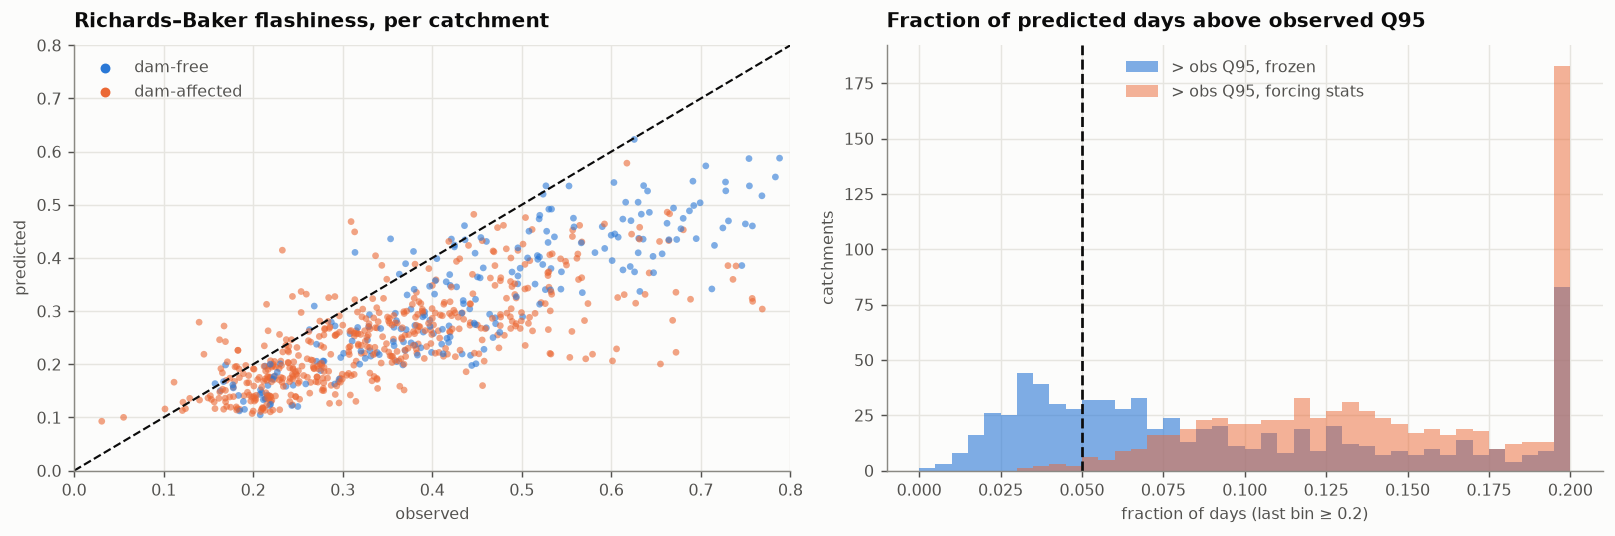

In [15]:
def rb_index(arr):
    d = np.abs(np.diff(arr, axis=1))
    ok = np.isfinite(d) & np.isfinite(arr[:, 1:])
    return np.where(ok, d, 0).sum(1) / np.where(ok, arr[:, 1:], 0).sum(1)

rb_o, rb_p = rb_index(O[good]), rb_index(P[good])
q95, q99 = np.nanquantile(O[good], .95, axis=1), np.nanquantile(O[good], .99, axis=1)
f95, f99 = (P[good] > q95[:, None]).mean(1), (P[good] > q99[:, None]).mean(1)
f95_fo, f99_fo = (P_fo[good] > q95[:, None]).mean(1), (P_fo[good] > q99[:, None]).mean(1)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax.scatter(rb_o, rb_p, s=14, c=ax2col, alpha=.6, edgecolors="none")
ax.plot([0, 1], [0, 1], color=INK, lw=1.2, ls="--"); ax.set_xlim(0, .8); ax.set_ylim(0, .8)
for col, lab in ((BLUE, "dam-free"), (ORANGE, "dam-affected")):
    ax.scatter([], [], color=col, s=20, label=lab)
style(ax, "Richards–Baker flashiness, per catchment", "predicted", "observed")
ax.legend(frameon=False, labelcolor=INK2, loc="upper left")

bins = np.linspace(0, .2, 41)
bx.hist(f95.clip(max=.2), bins=bins, color=BLUE, alpha=.6, label="> obs Q95, frozen")
bx.hist(f95_fo.clip(max=.2), bins=bins, color=ORANGE, alpha=.5, label="> obs Q95, forcing stats")
bx.axvline(.05, color=INK, lw=1.5, ls="--")
style(bx, "Fraction of predicted days above observed Q95", "catchments", "fraction of days (last bin ≥ 0.2)")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()
print(f"median RB index: observed {np.nanmedian(rb_o):.3f} | predicted {np.nanmedian(rb_p):.3f}")
print(f"  dam-free     obs {np.nanmedian(rb_o[in_training[good]]):.3f} pred {np.nanmedian(rb_p[in_training[good]]):.3f}")
print(f"  dam-affected obs {np.nanmedian(rb_o[~in_training[good]]):.3f} pred {np.nanmedian(rb_p[~in_training[good]]):.3f}")
print(f"days above obs Q95 — frozen {100*np.median(f95):.1f}% | forcing {100*np.median(f95_fo):.1f}%  (target 5%)")
print(f"days above obs Q99 — frozen {100*np.median(f99):.2f}% | forcing {100*np.median(f99_fo):.2f}%  (target 1%)")

## 12. Does the bias depend on river size?

Mean-flow ratio against observed mean flow. If the error grew with size it would point at routing
(water arriving too late or too spread out down a long network); a flat cloud points back at the
forcing.

binned median ratio, small → large: [1.14 0.97 0.99 1.11 1.26 1.22 1.23 1.42]
dam-free      0–5: n=106 ratio 0.99 | 5–20: n= 85 ratio 1.08 | 20–100: n= 32 ratio 0.93 | 100–inf: n=  0
dam-affected  0–5: n= 27 ratio 1.17 | 5–20: n=148 ratio 1.28 | 20–100: n=231 ratio 1.31 | 100–inf: n=102 ratio 1.37


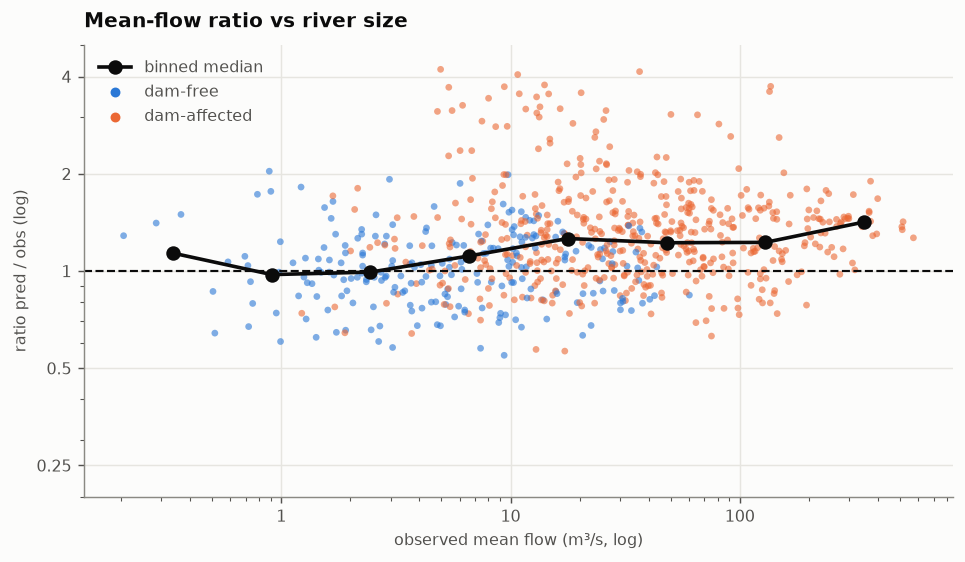

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
om_g, rm_g = stats["obs_mean"].values[good], r_mean
ax.scatter(om_g, rm_g, s=14, c=ax2col, alpha=.6, edgecolors="none")
ax.axhline(1, color=INK, lw=1.2, ls="--")
edges = np.logspace(np.log10(np.nanmin(om_g[om_g > 0])), np.log10(np.nanmax(om_g)), 9)
mid = np.sqrt(edges[:-1] * edges[1:])
med = [np.nanmedian(rm_g[(om_g >= lo) & (om_g < hi)]) for lo, hi in zip(edges[:-1], edges[1:])]
ax.plot(mid, med, "o-", color=INK, lw=2, ms=7, label="binned median")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(.2, 5)
ratio_ticks(ax, "y")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
for col, lab in ((BLUE, "dam-free"), (ORANGE, "dam-affected")):
    ax.scatter([], [], color=col, s=20, label=lab)
style(ax, "Mean-flow ratio vs river size", "ratio pred / obs (log)", "observed mean flow (m³/s, log)")
ax.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()
print("binned median ratio, small → large:", np.round(med, 2))
dfg = in_training[good]
for lab, m in (("dam-free", dfg), ("dam-affected", ~dfg)):
    row = [f"{lo:g}–{hi:g}: n={k.sum():3d} ratio {np.nanmedian(rm_g[k]):.2f}" if k.sum() else f"{lo:g}–{hi:g}: n=  0"
           for lo, hi in ((0, 5), (5, 20), (20, 100), (100, np.inf))
           for k in [m & (om_g >= lo) & (om_g < hi)]]
    print(f"{lab:13s} " + " | ".join(row))

## Part II — conclusions

1. **The spring/snowmelt half of the year looks right; the summer–autumn flood half is missing.**
   In the hydrographs (§7–8), the March–May melt rise has the right shape, timing and roughly the
   right height, even at the big northern rivers. What HiRO-ACE doesn't produce is the sharp
   July–October rain floods: at the southern typhoon-season gauge (2) observed peaks reach
   ~3,000 m³/s while predicted summer peaks barely leave baseflow. Same story as Part I's
   Jul–Sep precipitation deficit, now visible event by event.
2. **Floods come in the wrong season and are too small, even though mean flow is too high.**
   July holds ~28% of observed annual maxima but only ~10% of predicted ones; predicted maxima move
   to April–June (snowmelt/Baiu). Median annual peak ratio ≈0.87 against a mean-flow ratio ≈1.18,
   so a mean-only bias correction would make floods *worse*.
3. **The hydrograph is too smooth day to day.** Richards–Baker flashiness ≈0.26 predicted vs ≈0.36
   observed, for dam-free and dam-affected catchments alike — the day-scale version of the low CV
   in §5. Frozen stats still put ~7.5% of days above observed Q95 (target 5%): what's
   over-represented is long stretches of elevated flow (melt season), not sharp peaks. Forcing
   stats push that to ~14%.
4. **Interannual variability is realistic and there's no visible drift.** Year-to-year CV of
   annual mean flow ≈0.19 predicted vs ≈0.20 observed; the trend in the predicted annual medians
   (≈−1% per year) is small against ±10–20% year-to-year swings over 8 years. Individual
   predicted years (e.g. the dry 2018) mean nothing — it's a scenario.
5. **The apparent growth of bias with river size is entirely the dam effect.** Split by dam
   status, dam-free catchments sit at a median ratio of 0.93–1.08 in every size class, and
   dam-affected ones at 1.17–1.37 in every size class; the binned curve rises only because
   every gauge above ~100 m³/s has a dam upstream (§12). No sign of a routing problem. Dam-affected
   rivers are also where observed flow is visibly regulated (gauge 4: flat observed line against
   a flashy prediction) — expected, since reservoirs aren't modelled.

**For bias correction:** on the daily series averaged over gauged catchments, the Jul–Sep
precipitation deficit is broad, not confined to heavy-rain days (HiRO-ACE / real ≈0.57 at the
median, 0.60 at q90, 0.73 at q99; June is ≈1 throughout). So per-calendar-month quantile mapping
over the whole distribution is the right shape of fix. Whether *catchment-scale* daily extremes
are additionally too weak can't be checked from these outputs (spatial averaging smooths them,
and real per-catchment daily precipitation isn't saved); worth checking when the BC is built.